<a href="https://colab.research.google.com/github/Kusuma-Ramesh/cricbuzz-livestats/blob/main/Cricbuzz_LiveStats_Project_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cricbuzz LiveStats — Real-Time Cricket Insights & SQL-Based Analytics

**Project:** Cricbuzz LiveStats  
**Purpose:** Explore cricket match and player data, inspect the SQLite database, demonstrate SQL-based analytics, and validate the data layer used by the Streamlit application.  
**Technology:** Python, pandas, SQLite, SQL, Streamlit, Cricbuzz Cricket API (RapidAPI), Matplotlib.

**Project repository:** [Kusuma-Ramesh/cricbuzz-livestats](https://github.com/Kusuma-Ramesh/cricbuzz-livestats)

## 1. Set up the Colab environment

Run this cell in a fresh Google Colab runtime. It clones the public repository and installs the dependencies declared by the project.

In [ ]:
from pathlib import Path
import os
import sys
import subprocess

REPO_URL = "https://github.com/Kusuma-Ramesh/cricbuzz-livestats.git"
REPO_DIR = Path("/content/cricbuzz-livestats")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=False)

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

print("Repository:", REPO_DIR)
print("README exists:", (REPO_DIR / "README.md").exists())
print("Project files:", len(list(REPO_DIR.rglob("*.py"))), "Python files")

Repository: /content/cricbuzz-livestats
README exists: True
Project files: 37 Python files


## 2. Install project dependencies

The repository requirements are the source of truth for application dependencies. Installation can take a few minutes in a new runtime.

In [ ]:
install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-r", "requirements.txt"],
    text=True,
    capture_output=True,
)
print(install.stdout[-5000:])
if install.returncode != 0:
    print(install.stderr[-5000:])
    raise RuntimeError("Dependency installation failed; review the output above.")
print("Dependencies installed successfully.")

3/dist-packages (from streamlit>=1.50->-r requirements.txt (line 1)) (6.33.6)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 56.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 71.9 MB/s  0:00:00


Dependencies installed successfully.


## 3. Initialize the project database

The application uses SQLite. The project seed script creates/populates the local demo database. This does not call the live Cricbuzz API or require an API key.

In [ ]:
seed = subprocess.run(
    [sys.executable, "scripts/seed_database.py"],
    cwd=REPO_DIR,
    text=True,
    capture_output=True,
)
print(seed.stdout[-5000:])
if seed.returncode != 0:
    print(seed.stderr[-5000:])
    raise RuntimeError("Database seeding failed. Check the project script output above.")
print("Database seed script completed.")

Seeding sqlite:////content/cricbuzz-livestats/data/cricbuzz.db ...
  teams           10
  venues          32
  players        150
  series         366
  matches      1,330
  batting     24,125
  bowling     17,916
  fielding     9,441
Done.

Database seed script completed.


## 4. Imports and reproducibility settings

In [ ]:
import sqlite3
import re
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 140)

DB_PATH = REPO_DIR / "data" / "cricbuzz.db"
print("Database path:", DB_PATH)
print("Database exists:", DB_PATH.exists())
print("pandas:", pd.__version__)
if not DB_PATH.exists():
    raise FileNotFoundError(
        f"Expected {DB_PATH}. Review the seed output and the repository's database configuration."
    )

Database path: /content/cricbuzz-livestats/data/cricbuzz.db
Database exists: True
pandas: 2.2.3


## 5. Database schema inspection

Rather than assuming table names or column layouts, this section discovers them from the SQLite database created by the project.

In [ ]:
def get_connection(read_only=False):
    if read_only:
        uri = f"file:{DB_PATH.as_posix()}?mode=ro"
        return sqlite3.connect(uri, uri=True)
    return sqlite3.connect(DB_PATH)

with get_connection(read_only=True) as conn:
    tables_df = pd.read_sql_query(
        "SELECT name AS table_name, type FROM sqlite_master "
        "WHERE type IN ('table', 'view') AND name NOT LIKE 'sqlite_%' "
        "ORDER BY type, name",
        conn,
    )
display(tables_df)
if tables_df.empty:
    raise RuntimeError("No user tables or views were found in the SQLite database.")

,table_name,type
0,audit_log,table
1,batting_performances,table
2,bowling_performances,table
3,fielding_performances,table
4,matches,table
5,player_career_stats,table
6,players,table
7,series,table
8,teams,table
9,venues,table


In [ ]:
schema_rows = []
with get_connection(read_only=True) as conn:
    for table_name in tables_df["table_name"]:
        # Names originate from sqlite_master; quote them safely for PRAGMA.
        safe_name = table_name.replace('"', '""')
        cols = conn.execute(f'PRAGMA table_info("{safe_name}")').fetchall()
        for col in cols:
            schema_rows.append({
                "table": table_name,
                "column": col[1],
                "type": col[2],
                "not_null": bool(col[3]),
                "primary_key_position": col[5],
            })
schema_df = pd.DataFrame(schema_rows)
display(schema_df)
print(f"Discovered {tables_df.shape[0]} tables/views and {schema_df.shape[0]} columns.")

,table,column,type,not_null,primary_key_position
0,audit_log,log_id,INTEGER,True,1
1,audit_log,action,VARCHAR(10),True,0
2,audit_log,entity,VARCHAR(20),True,0
3,audit_log,entity_id,INTEGER,False,0
4,audit_log,detail,VARCHAR(400),False,0
...,...,...,...,...,...
101,v_player_leaderboard,country,VARCHAR(60),False,0
102,v_player_leaderboard,playing_role,VARCHAR(30),False,0
103,v_player_leaderboard,runs,,False,0
104,v_player_leaderboard,wickets,,False,0


Discovered 12 tables/views and 106 columns.


## 6. Row counts and sample records

The following cells provide a compact data inventory and show a few rows per table. Table and column names are discovered from the database, so this section adapts to the repository schema.

,table,row_count
1,batting_performances,24125
2,bowling_performances,17916
3,fielding_performances,9441
4,matches,1330
10,v_match_results,1330
5,player_career_stats,450
7,series,366
6,players,150
11,v_player_leaderboard,150
9,venues,32


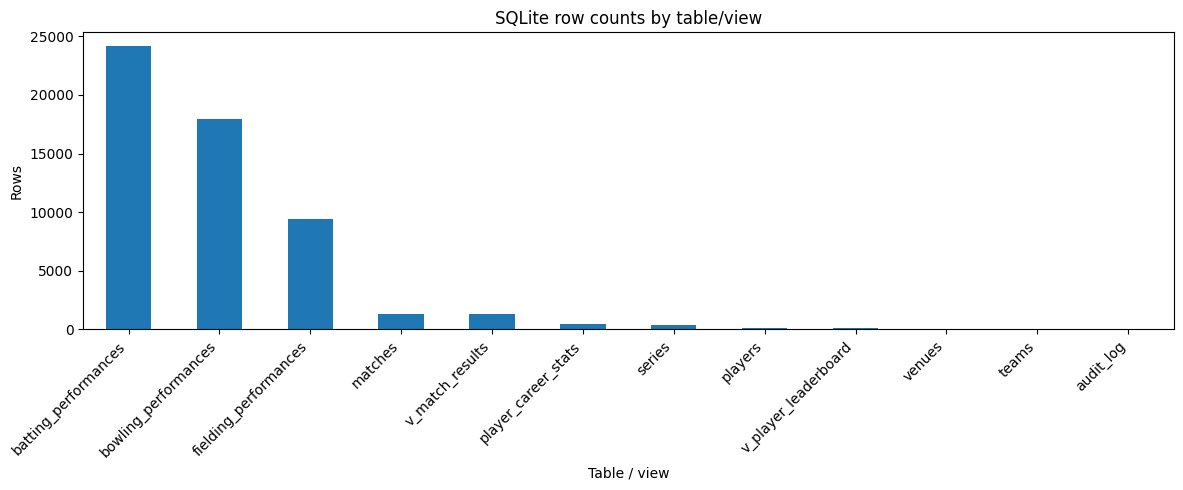

In [ ]:
row_counts = []
with get_connection(read_only=True) as conn:
    for table_name in tables_df["table_name"]:
        safe_name = table_name.replace('"', '""')
        try:
            count = conn.execute(f'SELECT COUNT(*) FROM "{safe_name}"').fetchone()[0]
            row_counts.append({"table": table_name, "row_count": count})
        except sqlite3.DatabaseError as exc:
            row_counts.append({"table": table_name, "row_count": None, "note": str(exc)})
row_counts_df = pd.DataFrame(row_counts).sort_values("row_count", ascending=False, na_position="last")
display(row_counts_df)

if not row_counts_df.empty:
    ax = row_counts_df.dropna(subset=["row_count"]).plot(
        x="table", y="row_count", kind="bar", legend=False, figsize=(12, 5)
    )
    ax.set_title("SQLite row counts by table/view")
    ax.set_xlabel("Table / view")
    ax.set_ylabel("Rows")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [ ]:
with get_connection(read_only=True) as conn:
    for table_name in tables_df["table_name"]:
        safe_name = table_name.replace('"', '""')
        print(f"\n### {table_name} — first 5 rows")
        try:
            sample = pd.read_sql_query(f'SELECT * FROM "{safe_name}" LIMIT 5', conn)
            display(sample)
        except Exception as exc:
            print("Could not display sample:", exc)


### audit_log — first 5 rows


,log_id,action,entity,entity_id,detail,created_at



### batting_performances — first 5 rows


,perf_id,match_id,innings_no,player_id,team_id,batting_position,runs,balls_faced,fours,sixes,strike_rate,is_out
0,1,1,1,76,6,1,6,5,0,0,120.00,1
1,2,1,1,77,6,2,1,4,0,0,25.00,1
2,3,1,1,78,6,3,0,2,0,0,0.00,1
3,4,1,1,79,6,4,145,177,11,1,81.92,1
4,5,1,1,80,6,5,28,35,2,0,80.00,1



### bowling_performances — first 5 rows


...

,venue_id,venue_name,city,country,capacity
0,1,Narendra Modi Stadium,Ahmedabad,India,132000
1,2,Eden Gardens,Kolkata,India,68000
2,3,MA Chidambaram Stadium,Chennai,India,50000
3,4,M. Chinnaswamy Stadium,Bengaluru,India,40000
4,5,Wankhede Stadium,Mumbai,India,33100



### v_match_results — first 5 rows


,match_id,match_date,match_format,description,team1,team2,winner,victory_margin,victory_type,venue_name,city,venue_country
0,1,2019-02-20,ODI,"PAK vs NZ, 1st ODI",Pakistan,New Zealand,New Zealand,5,wickets,Hagley Oval,Christchurch,New Zealand
1,2,2019-02-23,ODI,"NZ vs PAK, 2nd ODI",New Zealand,Pakistan,Pakistan,19,runs,Eden Park,Auckland,New Zealand
2,3,2019-02-26,ODI,"NZ vs PAK, 3rd ODI",New Zealand,Pakistan,New Zealand,68,runs,Basin Reserve,Wellington,New Zealand
3,4,2019-02-28,T20I,"SA vs NZ, 1st T20I",South Africa,New Zealand,New Zealand,1,wickets,Wanderers Stadium,Johannesburg,South Africa
4,5,2019-03-02,T20I,"NZ vs SA, 2nd T20I",New Zealand,South Africa,South Africa,4,wickets,Wanderers Stadium,Johannesburg,South Africa



### v_player_leaderboard — first 5 rows


,player_id,full_name,country,playing_role,runs,wickets,matches
0,1,Arjun Desai,India,Batsman,14182,0,251
1,2,Varun Pillai,India,Batsman,14004,0,254
2,3,Ayush Nair,India,Batsman,10887,0,237
3,4,Rahul Desai,India,Batsman,10568,0,226
4,5,Yash Kapoor,India,Wicket-keeper,7914,0,192


## 7. Data quality checks

These checks are descriptive and non-destructive: empty tables, duplicate column-level values, and null-heavy columns are reported for review. They do not modify the database.

In [ ]:
quality_rows = []
with get_connection(read_only=True) as conn:
    for table_name in tables_df["table_name"]:
        safe_name = table_name.replace('"', '""')
        frame = pd.read_sql_query(f'SELECT * FROM "{safe_name}"', conn)
        for col in frame.columns:
            quality_rows.append({
                "table": table_name,
                "column": col,
                "rows": len(frame),
                "null_count": int(frame[col].isna().sum()),
                "null_percent": round(float(frame[col].isna().mean() * 100), 2) if len(frame) else 0.0,
                "distinct_non_null": int(frame[col].nunique(dropna=True)),
            })
quality_df = pd.DataFrame(quality_rows)
display(quality_df.sort_values(["null_percent", "table"], ascending=[False, True]).head(40))

,table,column,rows,null_count,null_percent,distinct_non_null
60,player_career_stats,bowling_average,450,180,40.00,259
61,player_career_stats,economy_rate,450,180,40.00,213
69,players,bowling_style,150,60,40.00,8
55,player_career_stats,batting_average,450,30,6.67,401
0,audit_log,log_id,0,0,0.00,0
1,audit_log,action,0,0,0.00,0
2,audit_log,entity,0,0,0.00,0
3,audit_log,entity_id,0,0,0.00,0
4,audit_log,detail,0,0,0.00,0
5,audit_log,created_at,0,0,0.00,0


## 8. Review the project's 25 SQL questions

The canonical query collection is stored in `sql/queries.sql`. This cell reads that project file and displays its numbered question/comment headings, rather than duplicating or silently changing the SQL definitions.

In [ ]:
QUERIES_PATH = REPO_DIR / "sql" / "queries.sql"
if not QUERIES_PATH.exists():
    raise FileNotFoundError(f"Expected SQL query file: {QUERIES_PATH}")
queries_text = QUERIES_PATH.read_text(encoding="utf-8")
query_headings = re.findall(r"(?im)^\s*--\s*(?:Q\s*\d+|Query\s*\d+)[^\n]*", queries_text)
print("SQL file:", QUERIES_PATH.relative_to(REPO_DIR))
print("Numbered query headings detected:", len(query_headings))
for heading in query_headings:
    print(heading.strip())
if not query_headings:
    print("No numbered headings matched the common '-- Q1: ...' format. Preview of SQL file:")
    print(queries_text[:5000])

SQL file: sql/queries.sql
Numbered query headings detected: 25
-- Q01 [Beginner] Players who represent India
-- Q02 [Beginner] Matches played in the last 30 days
-- Q03 [Beginner] Top 10 ODI run scorers
-- Q04 [Beginner] Stadiums with capacity above 50,000
-- Q05 [Beginner] Total wins by team
-- Q06 [Beginner] Players per playing role
-- Q07 [Beginner] Highest individual score in each format
-- Q08 [Beginner] Series that started in 2024
-- Q09 [Intermediate] All-rounders with 1,000+ runs and 50+ wickets
-- Q10 [Intermediate] Last 20 completed matches with results
-- Q11 [Intermediate] Players compared across formats
-- Q12 [Intermediate] Home vs away performance by team
-- Q13 [Intermediate] Partnerships of 100+ between consecutive batters
-- Q14 [Intermediate] Bowling performance by venue
-- Q15 [Intermediate] Players who thrive in close matches
-- Q16 [Intermediate] Year-by-year batting trend since 2020
-- Q17 [Advanced] Does winning the toss win the match?
-- Q18 [Advanced] Most eco

## 9. Execute a safe subset of SQL analytics

The examples below are generated from the discovered schema and are read-only. They show how to explore a table and aggregate row counts without assuming specific cricket table columns. The full 25-question collection remains in `sql/queries.sql` and is also available in the Streamlit SQL Analytics page.

In [ ]:

non_empty = row_counts_df[row_counts_df["row_count"].fillna(0) > 0]
if non_empty.empty:
    print("No non-empty tables were found to query.")
else:
    example_table = str(non_empty.iloc[0]["table"])
    safe_name = example_table.replace('"', '""')
    print("Example table:", example_table)
    with get_connection(read_only=True) as conn:
        example_df = pd.read_sql_query(f'SELECT * FROM "{safe_name}" LIMIT 10', conn)
    display(example_df)

Example table: batting_performances


,perf_id,match_id,innings_no,player_id,team_id,batting_position,runs,balls_faced,fours,sixes,strike_rate,is_out
0,1,1,1,76,6,1,6,5,0,0,120.00,1
1,2,1,1,77,6,2,1,4,0,0,25.00,1
2,3,1,1,78,6,3,0,2,0,0,0.00,1
3,4,1,1,79,6,4,145,177,11,1,81.92,1
4,5,1,1,80,6,5,28,35,2,0,80.00,1
5,6,1,1,81,6,6,23,29,2,0,79.31,0
6,7,1,1,82,6,7,38,48,3,0,79.17,0
7,8,1,2,61,5,1,89,94,4,0,94.68,1
8,9,1,2,62,5,2,4,4,0,0,100.00,1
9,10,1,2,63,5,3,15,17,1,0,88.24,1


In [ ]:

def run_read_only_sql(sql, params=None):
    """Execute one SELECT statement against SQLite in read-only mode."""
    statement = sql.strip()
    if not re.match(r"(?is)^SELECT\b", statement):
        raise ValueError("Only SELECT statements are permitted by this notebook helper.")
    if ";" in statement.rstrip(";"):
        raise ValueError("Run one SQL statement at a time.")
    with get_connection(read_only=True) as conn:
        return pd.read_sql_query(statement, conn, params=params or {})

display(run_read_only_sql(
    "SELECT type, COUNT(*) AS object_count "
    "FROM sqlite_master WHERE type IN ('table', 'view') GROUP BY type ORDER BY type"
))

,type,object_count
0,table,10
1,view,2


## 10. Cricket-oriented analytics (schema-aware)

The following cell looks for common cricket fields (such as runs, wickets, player, team, match, and venue) across the actual schema. It reports possible analytical columns so that subsequent analysis can be tied to fields that truly exist in this version of the database.

In [ ]:
def normalized(value):
    return re.sub(r"[^a-z0-9]", "", str(value).lower())

column_catalog = schema_df.copy()
column_catalog["normalized_column"] = column_catalog["column"].map(normalized)
semantic_groups = {
    "runs / score": {"runs", "run", "score", "totalruns", "battingruns"},
    "wickets": {"wickets", "wicket", "wkts"},
    "player": {"player", "playername", "fullname", "name", "batter", "bowler"},
    "team": {"team", "teamname", "battingteam", "bowlingteam", "winner"},
    "match": {"match", "matchid", "matchname", "matchdate", "startdate"},
    "venue": {"venue", "venuename", "stadium", "city"},
    "format": {"format", "matchformat", "matchtype", "type"},
}
semantic_matches = []
for semantic, candidates in semantic_groups.items():
    matches = column_catalog[column_catalog["normalized_column"].isin(candidates)]
    for _, row in matches.iterrows():
        semantic_matches.append({"concept": semantic, "table": row["table"], "column": row["column"], "type": row["type"]})
semantic_df = pd.DataFrame(semantic_matches)
if semantic_df.empty:
    print("No conventional field names matched automatically. Use the schema inventory above to inspect this project's actual naming.")
else:
    display(semantic_df)

,concept,table,column,type
0,runs / score,batting_performances,runs,INTEGER
1,runs / score,player_career_stats,total_runs,INTEGER
2,runs / score,v_player_leaderboard,runs,
3,wickets,bowling_performances,wickets,INTEGER
4,wickets,v_player_leaderboard,wickets,
5,player,players,full_name,VARCHAR(120)
6,player,v_player_leaderboard,full_name,VARCHAR(120)
7,team,teams,team_name,VARCHAR(80)
8,team,v_match_results,winner,VARCHAR(80)
9,match,batting_performances,match_id,INTEGER


## 11. Visualize a numeric field when available

This cell selects a numeric column from a table only when the SQLite schema indicates one exists. It makes a simple distribution plot and avoids inventing cricket statistics when no suitable numeric field is present.

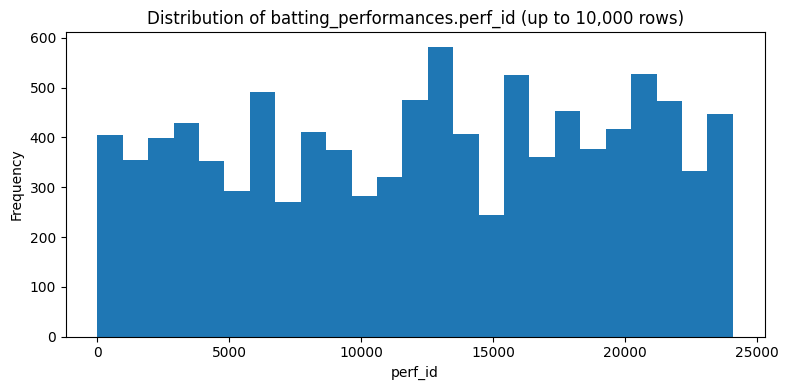

In [ ]:
numeric_types = {"INT", "INTEGER", "REAL", "FLOAT", "DOUBLE", "NUMERIC", "DECIMAL"}
numeric_candidates = schema_df[
    schema_df["type"].fillna("").str.upper().map(lambda t: any(token in t for token in numeric_types))
]
plot_done = False
with get_connection(read_only=True) as conn:
    for _, candidate in numeric_candidates.iterrows():
        table_name, column_name = str(candidate["table"]), str(candidate["column"])
        safe_table = table_name.replace('"', '""')
        safe_column = column_name.replace('"', '""')
        try:
            values = pd.read_sql_query(
                f'SELECT "{safe_column}" AS value FROM "{safe_table}" WHERE "{safe_column}" IS NOT NULL LIMIT 10000',
                conn,
            )["value"]
            values = pd.to_numeric(values, errors="coerce").dropna()
            if len(values) >= 2 and values.nunique() > 1:
                plt.figure(figsize=(8, 4))
                plt.hist(values, bins=25)
                plt.title(f"Distribution of {table_name}.{column_name} (up to 10,000 rows)")
                plt.xlabel(column_name)
                plt.ylabel("Frequency")
                plt.tight_layout()
                plt.show()
                plot_done = True
                break
        except Exception as exc:
            warnings.warn(f"Could not plot {table_name}.{column_name}: {exc}")
if not plot_done:
    print("No suitable numeric column with variation was found for a histogram.")

## 12. Inspect application SQL and database design artifacts

This section confirms the key source artifacts are present in the cloned repository. These files, rather than this notebook, remain authoritative for the app implementation.

In [ ]:
artifact_paths = [
    "main.py",
    "README.md",
    "requirements.txt",
    "pyproject.toml",
    "sql/schema.sql",
    "sql/sample_data.sql",
    "sql/queries.sql",
    "database/models.py",
    "database/seed.py",
    "scripts/seed_database.py",
    "services/analytics.py",
    "services/crud.py",
    "services/live_service.py",
    "api/cricbuzz_client.py",
    "api/parsers.py",
    "docs/ARCHITECTURE.md",
]
artifact_df = pd.DataFrame({"artifact": artifact_paths, "exists": [(REPO_DIR / p).exists() for p in artifact_paths]})
display(artifact_df)
print("All listed artifacts present:", bool(artifact_df["exists"].all()))

,artifact,exists
0,main.py,True
1,README.md,True
2,requirements.txt,True
3,pyproject.toml,True
4,sql/schema.sql,True
5,sql/sample_data.sql,True
6,sql/queries.sql,True
7,database/models.py,True
8,database/seed.py,True
9,scripts/seed_database.py,True


All listed artifacts present: True


## 13. Optional: run the project's automated tests

The repository README documents a pytest suite covering over notation, the SQL queries, CRUD validation, and SQL-console safety. This cell runs the tests as a validation step. If Colab dependency versions differ from the development environment, capture the failure output rather than claiming the tests passed.

In [ ]:
pytest_install = subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], text=True, capture_output=True)
if pytest_install.returncode != 0:
    print(pytest_install.stderr[-3000:])
    raise RuntimeError("Could not install pytest for the optional test run.")

test_run = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=REPO_DIR,
    text=True,
    capture_output=True,
)
print(test_run.stdout[-10000:])
if test_run.stderr:
    print("STDERR:")
    print(test_run.stderr[-5000:])
print("Pytest exit code:", test_run.returncode)
if test_run.returncode != 0:
    print("Some tests did not pass in this runtime. Review the output; do not report a successful test run.")

........................................................................ [ 60%]
...............................................                          [100%]
119 passed in 13.84s

Pytest exit code: 0


## 14. Live API integration — optional and credential-safe

Live API requests require a RapidAPI subscription/key and valid endpoint availability. Do not paste a secret key into a notebook cell or commit it to GitHub. The application reads `RAPIDAPI_KEY` from a local `.env` file or Streamlit secrets. For a Colab-only experiment, use Colab Secrets or `getpass` and never print the key. The API integration is intentionally not invoked automatically in this notebook to avoid accidental quota usage and because endpoint access may vary.

In [ ]:

RUN_LIVE_API_CHECK = False
if RUN_LIVE_API_CHECK:
    import getpass
    api_key = getpass.getpass("RapidAPI key (input hidden): ")
    print("A key was provided." if api_key else "No key entered.")
    print("For live requests, wire this secret into the project's supported configuration without displaying it.")
else:
    print("Live API check skipped. Database/demo analytics are available without credentials.")

Live API check skipped. Database/demo analytics are available without credentials.


## 16. Conclusion

Cricbuzz LiveStats combines a multi-page Streamlit interface with a SQLite data layer, cricket-oriented SQL analytics, CRUD workflows, and optional Cricbuzz API integration. This notebook documents the project database and analytical workflow using the repository as its source of truth. The seeded dataset is synthetic and useful for demonstrations and SQL practice; it must be clearly distinguished from verified live API data. Live match availability depends on credentials, API quota, and endpoint compatibility.

**Repository:** https://github.com/Kusuma-Ramesh/cricbuzz-livestats